In [69]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

They are a few problems in the dataset given :

    - No header : no first line to determine the name of the columns.
        -> we can fix it by specifing the column's name when we read the csv.
    - Missing values : color is missing in some rows.
        -> replace missing values by default 0x000000 (white).

In [70]:
df = pd.read_csv("Student_Dataset.csv", delimiter=",", on_bad_lines="warn", names=["id", "color", "testimony"], engine='python', header=None)

def fix_row(row) -> pd.Series:
    values        = row.dropna().tolist()
    id_val        = values[0]
    testimony_val = values[-1]
    color_val     = values[1] if len(values) > 2 else "0x000000"
    return pd.Series([id_val, color_val, testimony_val], index=["id", "color", "testimony"])

df_fixed = df.apply(fix_row, axis=1)

df_fixed.info()
df_fixed.head()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1011 entries, 0 to 1010
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         1011 non-null   int64 
 1   color      1011 non-null   object
 2   testimony  1011 non-null   object
dtypes: int64(1), object(2)
memory usage: 23.8+ KB


,id,color,testimony
0,1,0x000000,On uneven paths the heel feels wobbly side‑to‑...
1,2,0x000000,"The feverish feeling eased, but I’m now breath..."
2,3,0x000000,"While working in the garden, I touched a metal..."
3,4,0x000000,A short sprint brought on a twinge in the midd...
4,5,0x000000,I accidentally left my hand on a hot mug for a...


The trick here is that the "read_csv" automaticly put the tesminonies in the "color" column. So we need to force the testimonies to go in the last column and repace the value in "color" by default 0x000000 (white).

personnal : maybe add some other cleaning rules to optimize the data set

cannot use K-means because we don't konw how many categories they are


https://colab.research.google.com/drive/10jcxkl76JtUDWjHJJGjtITV4c-ducvAl#scrollTo=zaOU4LkIcbuc


https://youtu.be/NTsvXfT_wzA?si=jmFfT8ESEYRACQl2

(doc for clustering algo)



In [71]:
df_clean = df.dropna(subset=["testimony"]).copy()

corpus = df_clean["testimony"].astype(str).tolist()

def fix_color(c):
    if isinstance(c, str) and c.startswith("0x"):
        return "#" + c[2:]
    return "#000000"

colors = df_clean["color"].fillna("0x000000").apply(fix_color)

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words='english',
    token_pattern=r'(?u)\b[a-zA-Z]{3,}\b',
    max_df=0.5,
    min_df=5,
    ngram_range=(1, 2),
    max_features=3000
    )

custom_stopwords = ['ache', 'feel', 'area', 'pain']

vectorizer.stop_words_ = vectorizer.get_stop_words().union(custom_stopwords)

X = vectorizer.fit_transform(corpus)

vectorizer.get_feature_names_out()
print(X.shape)

(614, 511)



--- Silhouette Search ---
k=2, score=0.013854170634617784
k=3, score=0.014348686404561908
k=4, score=0.015803842165327767
k=5, score=0.019461898771197236
k=6, score=0.018799023785134806
k=7, score=0.019770640390099497
k=8, score=0.02064181963552964
k=9, score=0.022964675493202136

Best k: 9 with score 0.022964675493202136

--- Cluster Keywords ---
Cluster 0: ['brings', 'big toe', 'ache', 'air', 'arms', 'aches', 'ache outer', 'abdomen', 'appear', 'ankle']
Cluster 1: ['area', 'appeared', 'bad', 'appear', 'aches', 'arm', 'afternoon', 'accidentally', 'ache', 'abdomen']
Cluster 2: ['cold air', 'crusts', 'avoid', 'blister', 'bad', 'afternoon', 'ago', 'ache outer', 'ache', 'abdomen']
Cluster 3: ['blister', 'base', 'blisters', 'arms', 'big', 'began', 'ago', 'appears', 'aches', 'abdomen']
Cluster 4: ['days', 'chest feels', 'ankle', 'band', 'backward', 'appeared', 'air', 'aches', 'ago', 'abdomen']
Cluster 5: ['assumed', 'arms', 'bed', 'blisters', 'blocked', 'aches', 'accidentally', 'ache outer'

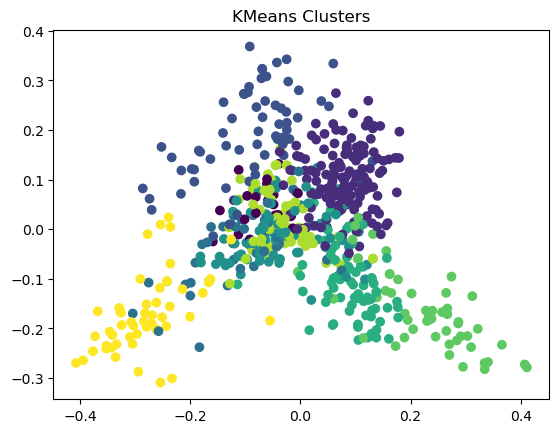

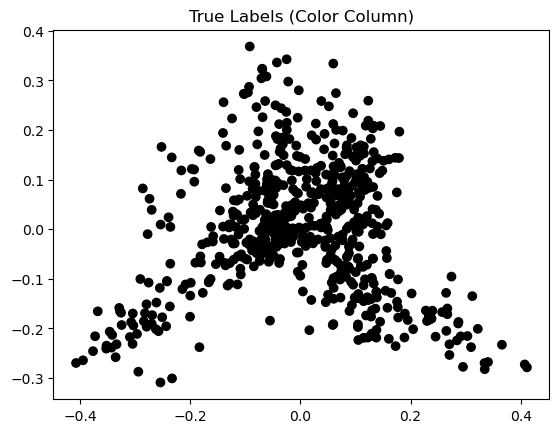

In [72]:
svd = TruncatedSVD(n_components=300, random_state=42)
X_reduced = svd.fit_transform(X)

# Normalize (VERY important)
normalizer = Normalizer()
X_reduced = normalizer.fit_transform(X_reduced)

# =========================
# 4. GRID SEARCH (K + SVD optional)
# =========================
best_score = -1
best_k = None

print("\n--- Silhouette Search ---")
for k in range(2, 10):
    model = AgglomerativeClustering(n_clusters=k)
    labels = model.fit_predict(X_reduced)
    
    score = silhouette_score(X_reduced, labels)
    print(f"k={k}, score={score}")
    
    if score > best_score:
        best_score = score
        best_k = k

print(f"\nBest k: {best_k} with score {best_score}")

# =========================
# 5. FINAL MODEL
# =========================
kmeans = KMeans(n_clusters=best_k, random_state=42)
labels = kmeans.fit_predict(X_reduced)

# =========================
# 6. INTERPRET CLUSTERS
# =========================
terms = vectorizer.get_feature_names_out()
centroids = kmeans.cluster_centers_

print("\n--- Cluster Keywords ---")
for i, center in enumerate(centroids):
    top_indices = center.argsort()[-10:]
    words = [terms[j] for j in top_indices]
    print(f"Cluster {i}: {words}")

# =========================
# 7. SHOW EXAMPLES
# =========================
print("\n--- Cluster Examples ---")
for i in range(best_k):
    print(f"\nCluster {i}:")
    cluster_texts = [corpus[j] for j in range(len(labels)) if labels[j] == i]
    
    for text in cluster_texts[:3]:
        print("-", text)

# =========================
# 8. EVALUATION WITH COLOR COLUMN
# =========================

df_clean["cluster"] = labels

le = LabelEncoder()
true_labels = le.fit_transform(df_clean["color"].fillna("unknown"))

ari = adjusted_rand_score(true_labels, df_clean["cluster"])
print("ARI:", ari)

# =========================
# 9. VISUALIZATION (PCA)
# =========================

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_reduced)

# Plot clusters
plt.figure()
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels)
plt.title("KMeans Clusters")
plt.show()

# Plot true colors (if available)
plt.figure()
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=colors)
plt.title("True Labels (Color Column)")
plt.show()